<a href="https://colab.research.google.com/github/Romanzilla/ML/blob/main/%D0%9B%D0%A07_%D0%9D%D0%B0%D0%B4%D1%96%D0%B9%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [5]:
# Варіант 1. Завантаження файлу в Google Colab
from google.colab import files
files.upload()
df = pd.read_csv('data.csv')
df.head()

Saving data.csv to data.csv


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [ ]:
# Варіант 2. Завантаження датасету через KaggleHub
# import kagglehub
# import os
# path = kagglehub.dataset_download('unmoved/cure-the-princess')
# df = pd.read_csv(os.path.join(path, 'data.csv'))
# df.head()

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [6]:
# TODO: виведіть перші рядки, структуру й розмір датасету
# Підказка: head(), info(), shape
print("Перші 5 рядків:")
display(df.head())
print("\nСтруктура датасету:")
df.info()
print(f"\nРозмір датасету: {df.shape}")

Перші 5 рядків:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0



Структура датасету:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB

Розмір датасету: (2338, 14)


In [7]:
# TODO: перевірте кількість пропусків і дублікатів
# Підказка: isnull().sum(), duplicated().sum()
print("\nКількість пропусків у кожній колонці:")
print(df.isnull().sum())
print(f"\nКількість дублікатів: {df.duplicated().sum()}")


Кількість пропусків у кожній колонці:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів: 0


In [8]:
# TODO: виведіть описову статистику
# Підказка: describe()
print("\nОписова статистика:")
display(df.describe())


Описова статистика:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
 Набір даних містить 2338 рядків і є повністю заповненим (без пропусків чи дублікатів). Усі ознаки є числовими, а їхнє мінімальне значення дорівнює 1.0.


### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [9]:
# TODO: сформуйте X (ознаки) та y (Cured)
# TODO: створіть X_train, X_test, y_train, y_test
# Підказка: train_test_split(..., test_size=0.2, random_state=42)
X = df.drop('Cured', axis=1)
y = df['Cured']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### 5. Баланс класів на навчальній вибірці

In [10]:
# TODO: підрахуйте кількість спостережень кожного класу в y_train
print("Кількість спостережень кожного класу:")
print(y_train.value_counts())

Кількість спостережень кожного класу:
Cured
0    946
1    924
Name: count, dtype: int64


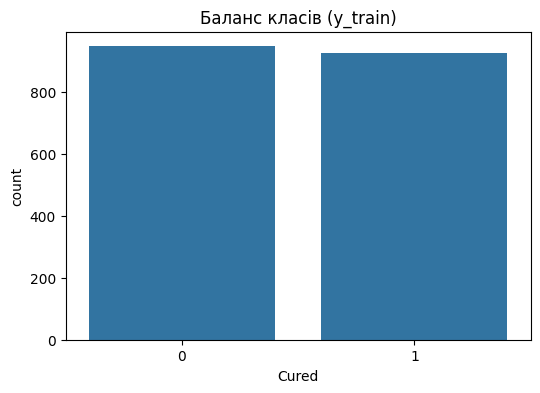

In [11]:
# TODO: побудуйте countplot для y_train
# Підказка: sns.countplot(x=y_train)
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title('Баланс класів (y_train)')
plt.show()

**Висновок:**  
_Чи збалансовані класи? Чому це може вплинути на оцінку моделі?_

Навчальна вибірка є збалансованою, адже графік демонструє практично однакову кількість спостережень для категорій 0 та 1 цільової змінної. Завдяки цьому модель не буде зміщена в бік переважаючого класу, що дозволяє впевнено застосовувати стандартну метрику Accuracy (точність) для об'єктивної оцінки її ефективності.


### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

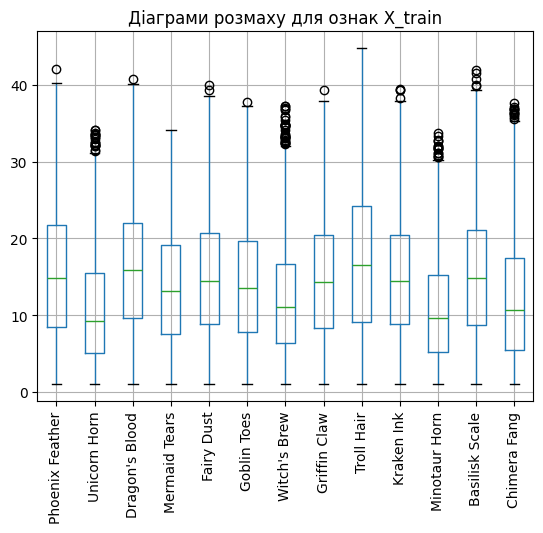

In [12]:
# TODO: побудуйте boxplot для X_train
# Підказка: X_train.boxplot(figsize=(13, 5), rot=90)
import matplotlib.pyplot as plt

plt.figure()
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title('Діаграми розмаху для ознак X_train')
plt.show()

In [13]:
# TODO: обчисліть q1, q3, iqr для X_train
# TODO: знайдіть кількість викидів за межами [q1 - 1.5*iqr, q3 + 1.5*iqr]
# TODO: відсортуйте результат за спаданням
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outliers = ((X_train < lower_bound) | (X_train > upper_bound)).sum()

outliers_sorted = outliers.sort_values(ascending=False)
print("Кількість потенційних викидів у кожній ознаці:")
print(outliers_sorted)

Кількість потенційних викидів у кожній ознаці:
Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
_У яких ознаках їх найбільше? Чому не варто без перевірки видаляти всі такі рядки?_

Найбільшу кількість потенційних аномалій зафіксовано в ознаках Witch's Brew (33), Unicorn Horn (20) та Minotaur Horn (18). Автоматичне вилучення цих записів без попереднього аналізу є небажаним, оскільки математичні викиди не обов'язково свідчать про помилки чи пошкодження даних. Вони часто відображають реальні екстремальні прояви досліджуваного процесу. Безпідставне видалення таких точок призведе до втрати цінної інформації, штучного зміщення розподілу та зниження прогностичної якості моделі на реальних, неідеальних даних.


### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

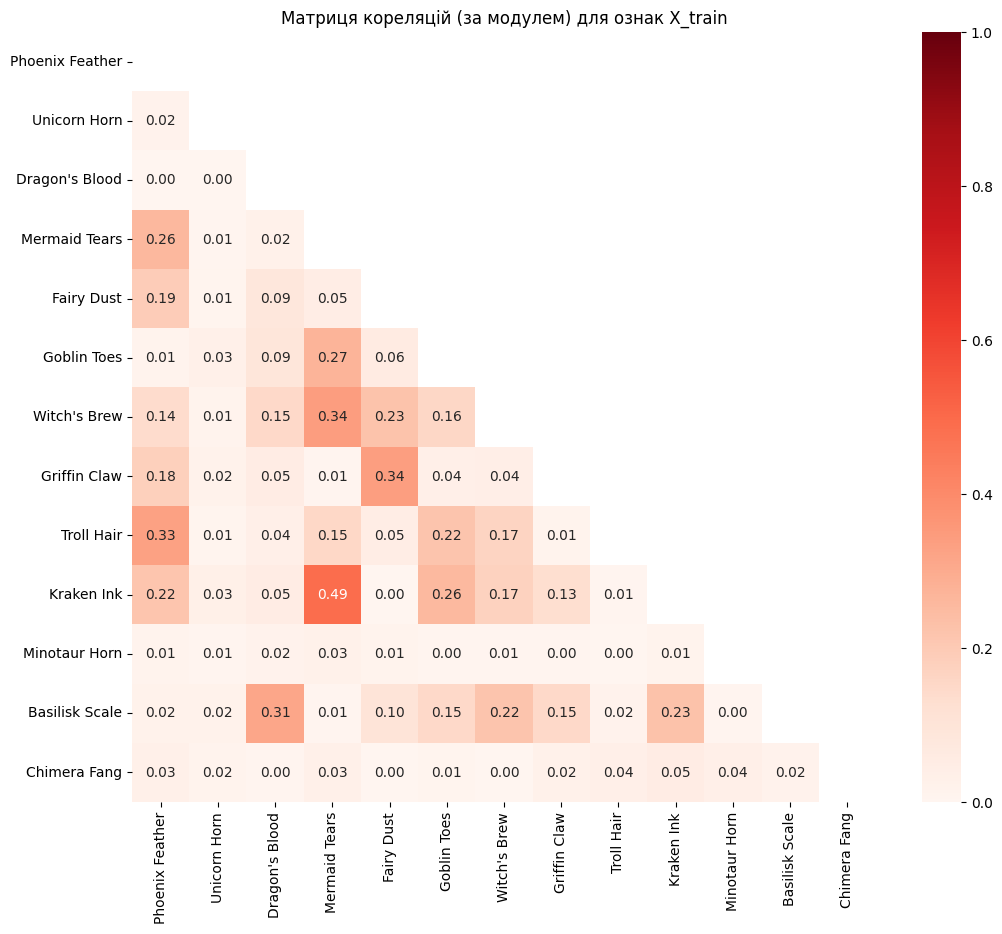

In [14]:
# TODO: обчисліть mtx = X_train.corr().abs()
# TODO: створіть маску верхнього трикутника за допомогою np.triu(...)
# TODO: побудуйте sns.heatmap(mtx, mask=..., annot=True, ...)
# Підказка: cmap='Reds', vmin=0, vmax=1
mtx = X_train.corr().abs()

mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(12, 10))
sns.heatmap(mtx, mask=mask, annot=True, cmap='Reds', vmin=0, vmax=1, fmt=".2f")
plt.title("Матриця кореляцій (за модулем) для ознак X_train")
plt.show()

In [15]:
# TODO: дослідіть кореляцію кожної ознаки із Cured
# Підказка: pd.concat([X_train, y_train], axis=1).corr()
train_data = pd.concat([X_train, y_train], axis=1)
corr_with_target = train_data.corr()['Cured'].drop('Cured').sort_values(ascending=False, key=abs)

print("Кореляція ознак із цільовою змінною Cured:")
print(corr_with_target)

Кореляція ознак із цільовою змінною Cured:
Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Basilisk Scale    -0.042277
Kraken Ink        -0.026598
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Griffin Claw      -0.005871
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Name: Cured, dtype: float64


**Висновок про кореляції:**  
_Назвіть пари найбільш корельованих ознак та ознаки з найсильнішим зв’язком із Cured._

Аналіз матриці виявив найвідчутніший взаємозв'язок між параметрами Kraken Ink та Mermaid Tears, де коефіцієнт досягає 0.49. Помітну лінійну залежність демонструють і такі пари: Witch's Brew та Mermaid Tears (0.34), Griffin Claw та Fairy Dust (0.34), Troll Hair та Phoenix Feather (0.33), а також Basilisk Scale та Dragon's Blood (0.31).
Щодо впливу на цільову змінну Cured, то тут беззаперечним лідером є ознака Troll Hair з показником близько 0.49. Другу позицію посідає Witch's Brew, коефіцієнт якої становить приблизно 0.25. Вплив решти параметрів на Cured є мінімальним і свідчить про дуже слабкий зв'язок.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [16]:
# TODO: створіть scaler = StandardScaler()
# TODO: отримайте X_train_scaled і X_test_scaled
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [17]:
# TODO: створіть model = LogisticRegression()
# TODO: model.fit(...)
# TODO: отримайте y_pred для X_test_scaled
# TODO: виведіть Accuracy та classification_report
model = LogisticRegression()

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8931623931623932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

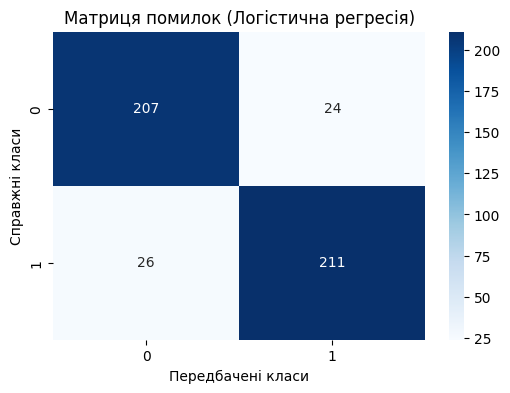

In [18]:
# TODO: обчисліть conf = confusion_matrix(y_test, y_pred)
# TODO: побудуйте теплову карту conf за допомогою sns.heatmap(...)
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.title('Матриця помилок (Логістична регресія)')
plt.xlabel('Передбачені класи')
plt.ylabel('Справжні класи')
plt.show()

In [19]:
# TODO: створіть DataFrame зі справжніми та передбаченими класами
# TODO: виведіть 10 випадкових рядків (sample(10, random_state=42))
results_df = pd.DataFrame({'Справжні': y_test, 'Передбачені': y_pred})

print("\n10 випадкових спостережень:")
display(results_df.sample(10, random_state=42))


10 випадкових спостережень:


,Справжні,Передбачені
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
_Яких помилок більше? Чи достатньо однієї метрики Accuracy?_

Модель логістичної регресії продемонструвала високу загальну точність (Accuracy = 89.3%). Аналіз матриці помилок виявив практично рівномірний розподіл хибних спрацьовувань: 26 помилок типу False Negative та 24 — False Positive. Зважаючи на збалансованість класів у датасеті та припущення про рівнозначну ціну помилок обох типів, метрика Accuracy є цілком репрезентативною для комплексної оцінки моделі. Ефективність такого підходу додатково підтверджується стабільно високими й однаковими значеннями precision, recall та f1-score для кожного з класів.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [20]:
# TODO: створіть словники param_grid і param_dist
# Наприклад, дослідіть кілька значень C, solver та max_iter
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 500, 1000]
}

param_dist = {
    'C': [0.001, 0.05, 0.5, 5, 50],
    'solver': ['lbfgs', 'liblinear', 'saga', 'newton-cg'],
    'max_iter': [100, 200, 500, 800, 1200]
}

In [21]:
# TODO: створіть GridSearchCV(LogisticRegression(), param_grid, cv=3, ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
grid_search = GridSearchCV(LogisticRegression(random_state=42), param_grid, cv=3, scoring='accuracy', n_jobs=-1)

grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри (GridSearchCV):", grid_search.best_params_)

Найкращі параметри (GridSearchCV): {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}


In [22]:
# TODO: створіть RandomizedSearchCV(LogisticRegression(), ...)
# TODO: виконайте fit(X_train_scaled, y_train)
# TODO: виведіть найкращі параметри
random_search = RandomizedSearchCV(LogisticRegression(random_state=42), param_distributions=param_dist, n_iter=10, cv=3, scoring='accuracy', random_state=42, n_jobs=-1)

random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри (RandomizedSearchCV):", random_search.best_params_)

Найкращі параметри (RandomizedSearchCV): {'solver': 'newton-cg', 'max_iter': 100, 'C': 50}


In [23]:
# TODO: отримайте найкращу модель з grid або random_search
# TODO: побудуйте прогноз на X_test_scaled
# TODO: виведіть Accuracy та classification_report
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test_scaled)

print("Accuracy (Tuned):", accuracy_score(y_test, y_pred_tuned))
print("\nClassification Report (Tuned):\n", classification_report(y_test, y_pred_tuned))

Accuracy (Tuned): 0.8931623931623932

Classification Report (Tuned):
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
_Який метод пошуку обрав які параметри? Чи покращилась якість порівняно з базовою моделлю?_

Оптимізація гіперпараметрів за допомогою методів GridSearchCV та RandomizedSearchCV не привела до покращення прогнозної сили моделі. GridSearchCV визначив оптимальними параметри {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}, тоді як RandomizedSearchCV обрав комбінацію {'solver': 'newton-cg', 'max_iter': 100, 'C': 50}. Попри ці розбіжності, якість класифікації на тестовій вибірці не змінилася: метрика Accuracy залишилася на рівні 89.3%, а показники precision, recall та f1-score виявилися повністю ідентичними результатам базової моделі. Такий збіг свідчить про те, що дефолтні налаштування логістичної регресії початково були близькими до оптимуму, тому подальший тюнінг виявився неефективним.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [24]:
# TODO: побудуйте SVC() і DecisionTreeClassifier(random_state=42)
# TODO: навчіть три моделі та отримайте їх передбачення
# TODO: створіть таблицю з Accuracy та F1-score для кожної моделі
# TODO: визначте найкращу модель
svc_model = SVC(random_state=42)
dt_model = DecisionTreeClassifier(random_state=42)

svc_model.fit(X_train_scaled, y_train)
dt_model.fit(X_train_scaled, y_train)

y_pred_lr = model.predict(X_test_scaled)
y_pred_svc = svc_model.predict(X_test_scaled)
y_pred_dt = dt_model.predict(X_test_scaled)

comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVC', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svc),
        accuracy_score(y_test, y_pred_dt)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svc),
        f1_score(y_test, y_pred_dt)
    ]
})

print(comparison_df)

                 Model  Accuracy  F1-score
0  Logistic Regression  0.893162  0.894068
1                  SVC  0.959402  0.960000
2        Decision Tree  0.865385  0.865672


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
1. Первинний аналіз даних: Вхідний датасет обсягом 2338 записів є повністю очищеним: у ньому відсутні дублікати або пропущені значення, а всі ознаки представлені в числовому форматі.
2. Аналіз викидів та кореляцій (на навчальній вибірці): Екстремальні значення зафіксовано в ознаках Witch's Brew, Unicorn Horn та Minotaur Horn. Їх вилучення визнано недоцільним, оскільки вони відображають реальні аномалії, а не технічні помилки. Кореляційний аналіз показав, що найсильніший лінійний зв'язок із цільовою змінною Cured має ознака Troll Hair. Явних ознак мультиколінеарності між факторами не виявлено.
3. Якість базової логістичної регресії: Модель «з коробки» продемонструвала високу ефективність із показником Accuracy близько 89.3%. При цьому помилки першого та другого родів (FP та FN) розподілилися майже рівномірно.
4. Вплив підбору гіперпараметрів: Тюнінг за допомогою методів GridSearchCV та RandomizedSearchCV не дав приросту в якості класифікації. Отримані моделі продублювали метрики базового алгоритму, що підтверджує оптимальність дефолтних налаштувань.
5. Обґрунтування найкращої моделі: Найбільш ефективним виявився метод опорних векторів (SVC), який перевершив інші моделі за метриками Accuracy та F1-score. Друге місце посіла логістична регресія, а найслабшу узагальнювальну здатність продемонструвало дерево рішень. Перевага SVC пояснюється його спроможністю формувати складні нелінійні розділяючі гіперповерхні у просторі ознак.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.